<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

-
-

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# Configuraciones de visualización
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [5]:
ruta = '/content/drive/MyDrive/BASES PARA IA/'
df_indicators = pd.read_csv(ruta + 'Indicators.csv')
df_countries = pd.read_csv(ruta + 'Country.csv')

In [6]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [7]:
print("\nInformación general del DataFrame:")
df_indicators.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [8]:
ruta = '/content/drive/MyDrive/BASES PARA IA/'
df_countries = pd.read_csv(ruta + 'Country.csv')

In [9]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(14, 3)


In [10]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CountryCode  14 non-null     object
 1   ShortName    14 non-null     object
 2   Region       14 non-null     object
dtypes: object(3)
memory usage: 468.0+ bytes


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [11]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [12]:
df_indicators['IndicatorCode'] = df_indicators['IndicatorCode'].replace(nombre_indicadores)


2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [13]:
df_pivot = df_indicators.pivot_table(index='CountryCode', columns='IndicatorCode', values='Value').reset_index()

2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [14]:
df_final = pd.merge(df_pivot, df_countries, on='CountryCode')


2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [15]:
df_final = df_final.drop(columns=['Region', 'CountryCode']).set_index('ShortName')
df_final.columns.name = None


### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [16]:
df_final.isna().sum()

,0
Agricultura (% del PIB),4
Comercio (% del PIB),3
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),4
Días para cumplir contratos,2
Exportaciones (US$),3
Facilidad para hacer negocios,5
Gasto en educación (% del PIB),3
Gasto en salud (% del PIB),4
Importaciones (US$),3


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [17]:
df_final_imputed = df_final.fillna(df_final.mean())
print(df_final_imputed.isna().sum().sum())


0


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

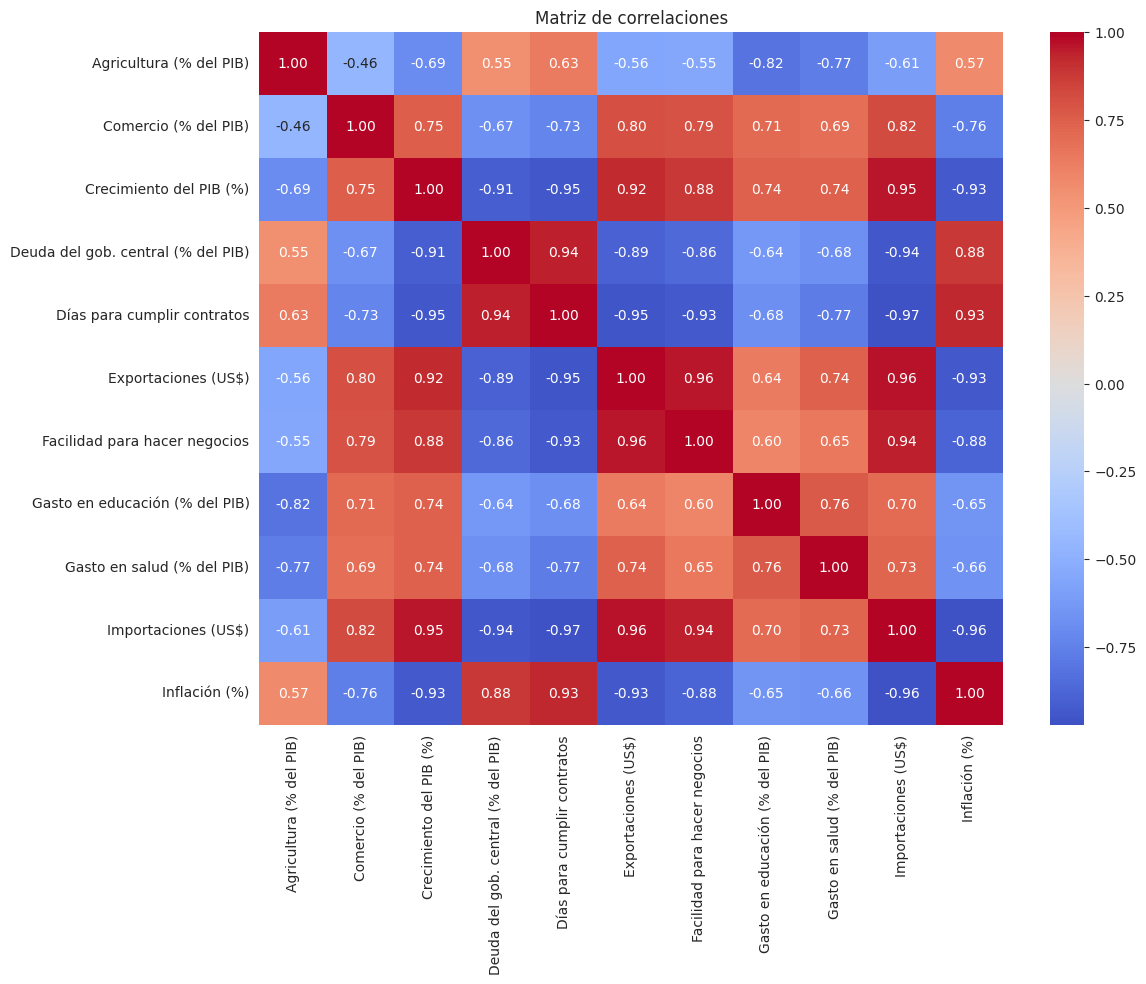

In [18]:
plt.figure(figsize=(12, 9))
sns.heatmap(df_final_imputed.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlaciones')
plt.show()

4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

Las variables presentan correlaciones muy fuertes entre sí la mayoría con |r| > 0.7, lo que evidencia un factor común y justifica el uso de PCA. Por un lado, exportaciones, importaciones, crecimiento del PIB, comercio y facilidad para hacer negocios se mueven juntos de forma positiva (por ejemplo, exportaciones e importaciones 0.96, exportaciones y facilidad para hacer negocios 0.96). Por otro lado, los días para cumplir contratos, la inflación y la deuda del gobierno se correlacionan negativamente con ese bloque (días para cumplir contratos e importaciones -0.97, inflación y crecimiento -0.93, deuda y crecimiento -0.91) y positivamente entre sí. Esto indica que los países con mejor desempeño económico y comercial tienden a tener mejores instituciones y mayor estabilidad macroeconómica. La agricultura (% del PIB) es la variable menos relacionada con el resto, aunque se asocia negativamente con el gasto en educación (-0.82) y salud (-0.77).

4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_final_imputed)


### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [20]:
pca = PCA()
pca.fit(X_scaled)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
print(varianza_acumulada)


[0.80432386 0.89486154 0.93597174 0.95991133 0.97641891 0.9864744
 0.99249496 0.99665217 0.99895635 0.99961687 1.        ]


5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

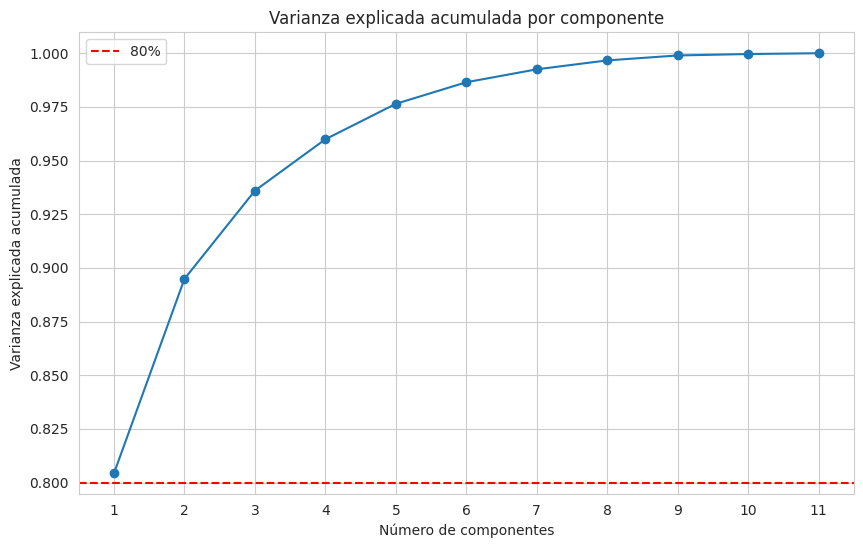

In [21]:
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o')
plt.axhline(0.8, color='r', linestyle='--', label='80%')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada por componente')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.legend()
plt.show()

5.3. Realiza un análisis del gráfico anterior.

El gráfico muestra que el primer componente principal por sí solo explica cerca del 80% de la varianza total 80.4%, es decir, un único componente resume la mayor parte de la información de las 11 variables originales. Con dos componentes la varianza acumulada llega a 89.5%, con tres a 93.6% y con cuatro a 96%, a partir de lo cual la curva se aplana y los componentes adicionales aportan muy poco cada uno menos del 2%. El salto grande entre el CP1 y el CP2 de 80% a 89.5% y el codo pronunciado de la curva indican que la información es altamente redundante, lo cual es coherente con las fuertes correlaciones observadas en el mapa de calor. Por lo tanto, es razonable reducir las 11 variables a un solo componente y usarlo como índice, ya que alcanza el umbral del 80% comúnmente aceptado, aunque se pierde cerca de un 20% de la información, que se podría recuperar si se retuviera un segundo componente.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [22]:
pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(X_scaled)
print(pca_final.explained_variance_ratio_)


[0.80432386]


6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

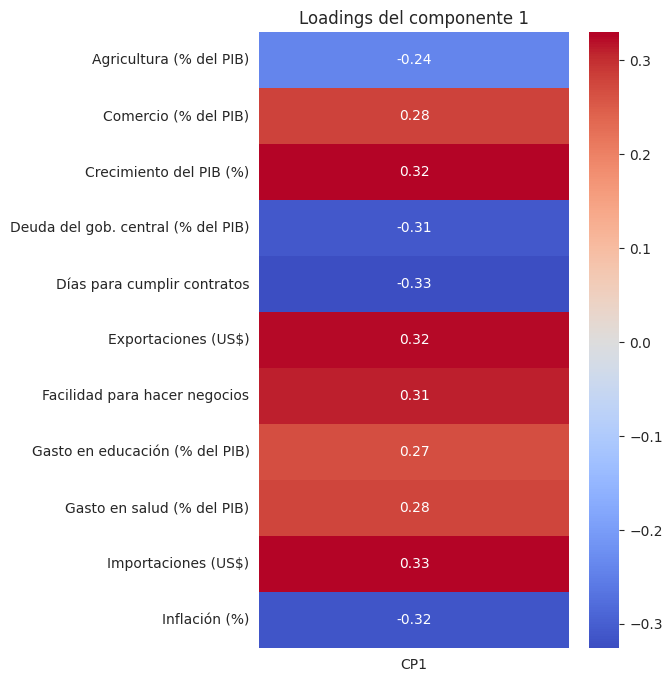

In [23]:
loadings = pd.DataFrame(pca_final.components_.T, index=df_final_imputed.columns, columns=['CP1'])
plt.figure(figsize=(5, 8))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Loadings del componente 1')
plt.show()


6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?

En el componente 1 todas las variables tienen cargas de magnitud similar. Las cargas altas y positivas corresponden a las importaciones, el crecimiento del PIB, las exportaciones y la facilidad para hacer negocios, mientras que las cargas altas y negativas corresponden a los días para cumplir contratos, la inflación y la deuda del gobierno central. Esto separa a los países con crecimiento, apertura comercial y estabilidad macroeconómica de aquellos con alta inflación, mucha deuda y justicia contractual lenta. Considero que el componente 1 sí puede usarse como índice del clima para la inversión, porque los signos tienen sentido económico, explica cerca del 80% de la varianza y el ranking es coherente, con Chile, Panamá y Costa Rica arriba y Argentina y Venezuela abajo. Aun así, debe usarse con cautela, porque mezcla variables de tamaño de la economía con variables de calidad institucional y omite factores como el riesgo político o los impuestos.

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [24]:
df_final['Indice_Inversion'] = X_pca[:, 0]
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,-5.93
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,-1.93
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [25]:
df_final = df_final.sort_values('Indice_Inversion', ascending=False)


7.2. Convierte 'ShortName' en una columna del dataframe.

In [26]:
df_final = df_final.reset_index()

7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

/tmp/ipykernel_1127/3176705206.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_final, x='Indice_Inversion', y='ShortName', palette='viridis')


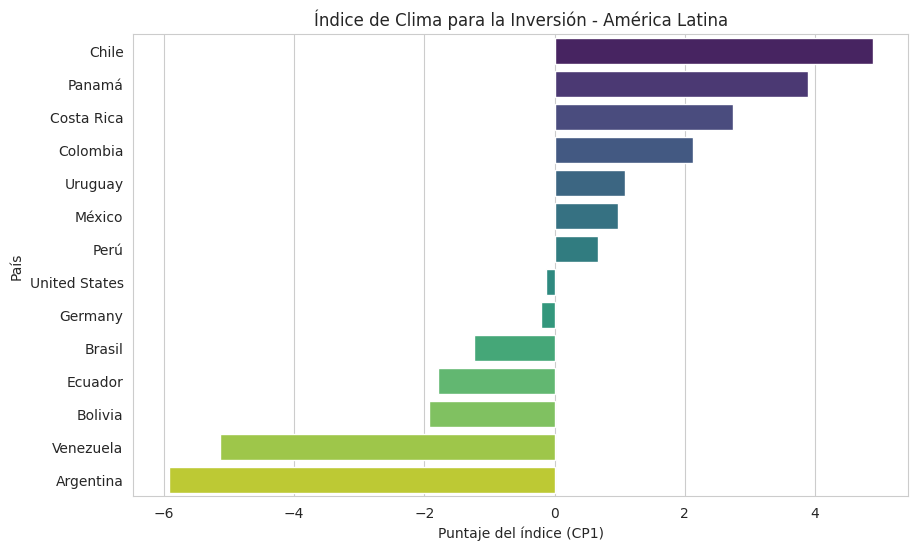

In [27]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df_final, x='Indice_Inversion', y='ShortName', palette='viridis')
plt.title('Índice de Clima para la Inversión - América Latina')
plt.xlabel('Puntaje del índice (CP1)')
plt.ylabel('País')
plt.show()


7.4. Analiza los resultados del gráfico y redacta una conclusiones para el MinCIT sobre el clima de inversión en la región, quiénes son nuestros competidores en la atracción de capitales extranjeros y por qué, en qué son mejores que Colombia.

Los resultados muestran un clima de inversión muy desigual en la región. Chile lidera con 4.89, seguido por Panamá con 3.89 y Costa Rica con 2.75, mientras que Colombia ocupa el cuarto lugar con 2.13, por encima de Uruguay, México y Perú. Argentina y Venezuela quedan al final, con puntajes cercanos a -5, por su alta inflación y su deterioro macroeconómico. Nuestros principales competidores en la atracción de inversión extranjera son entonces Chile, Panamá y Costa Rica, que superan a Colombia por tener un mejor entorno para hacer negocios, una justicia contractual más rápida, mayor apertura comercial y, en el caso de Panamá y Costa Rica, una inflación menor. Para cerrar esa brecha, Colombia debería priorizar la agilidad judicial, la simplificación regulatoria, el control de la inflación y una mayor integración comercial. Estos resultados deben tomarse con cautela, porque el índice se basa en un solo año y en el caso de Colombia las exportaciones y la facilidad para hacer negocios fueron imputadas con el promedio.